# Plan a Route

The planner's lifecycle: take a world's hazard forecast, a point A and a point B, and choose the segments to drive with a target speed on each.

The planner reads the forecast on the road graph and nothing else. It never sees the hazards rolled for a run.

In [1]:
from pathlib import Path

from pyotter import Planner, Visualize
from pyotter.core import WorldHazardLibrary, WorldRoadGraph
from pyotter.modules.planner import PlannerComputedWaypoints, PlannerConfig

OUTPUT = Path("runs")
OUTPUT.mkdir(exist_ok=True)

## The World

The same forecast as in `world_demo.ipynb`: pedestrians at two junctions, a wet road that is nearly certain, rain or fog half the time, and a low sun at 17:30.

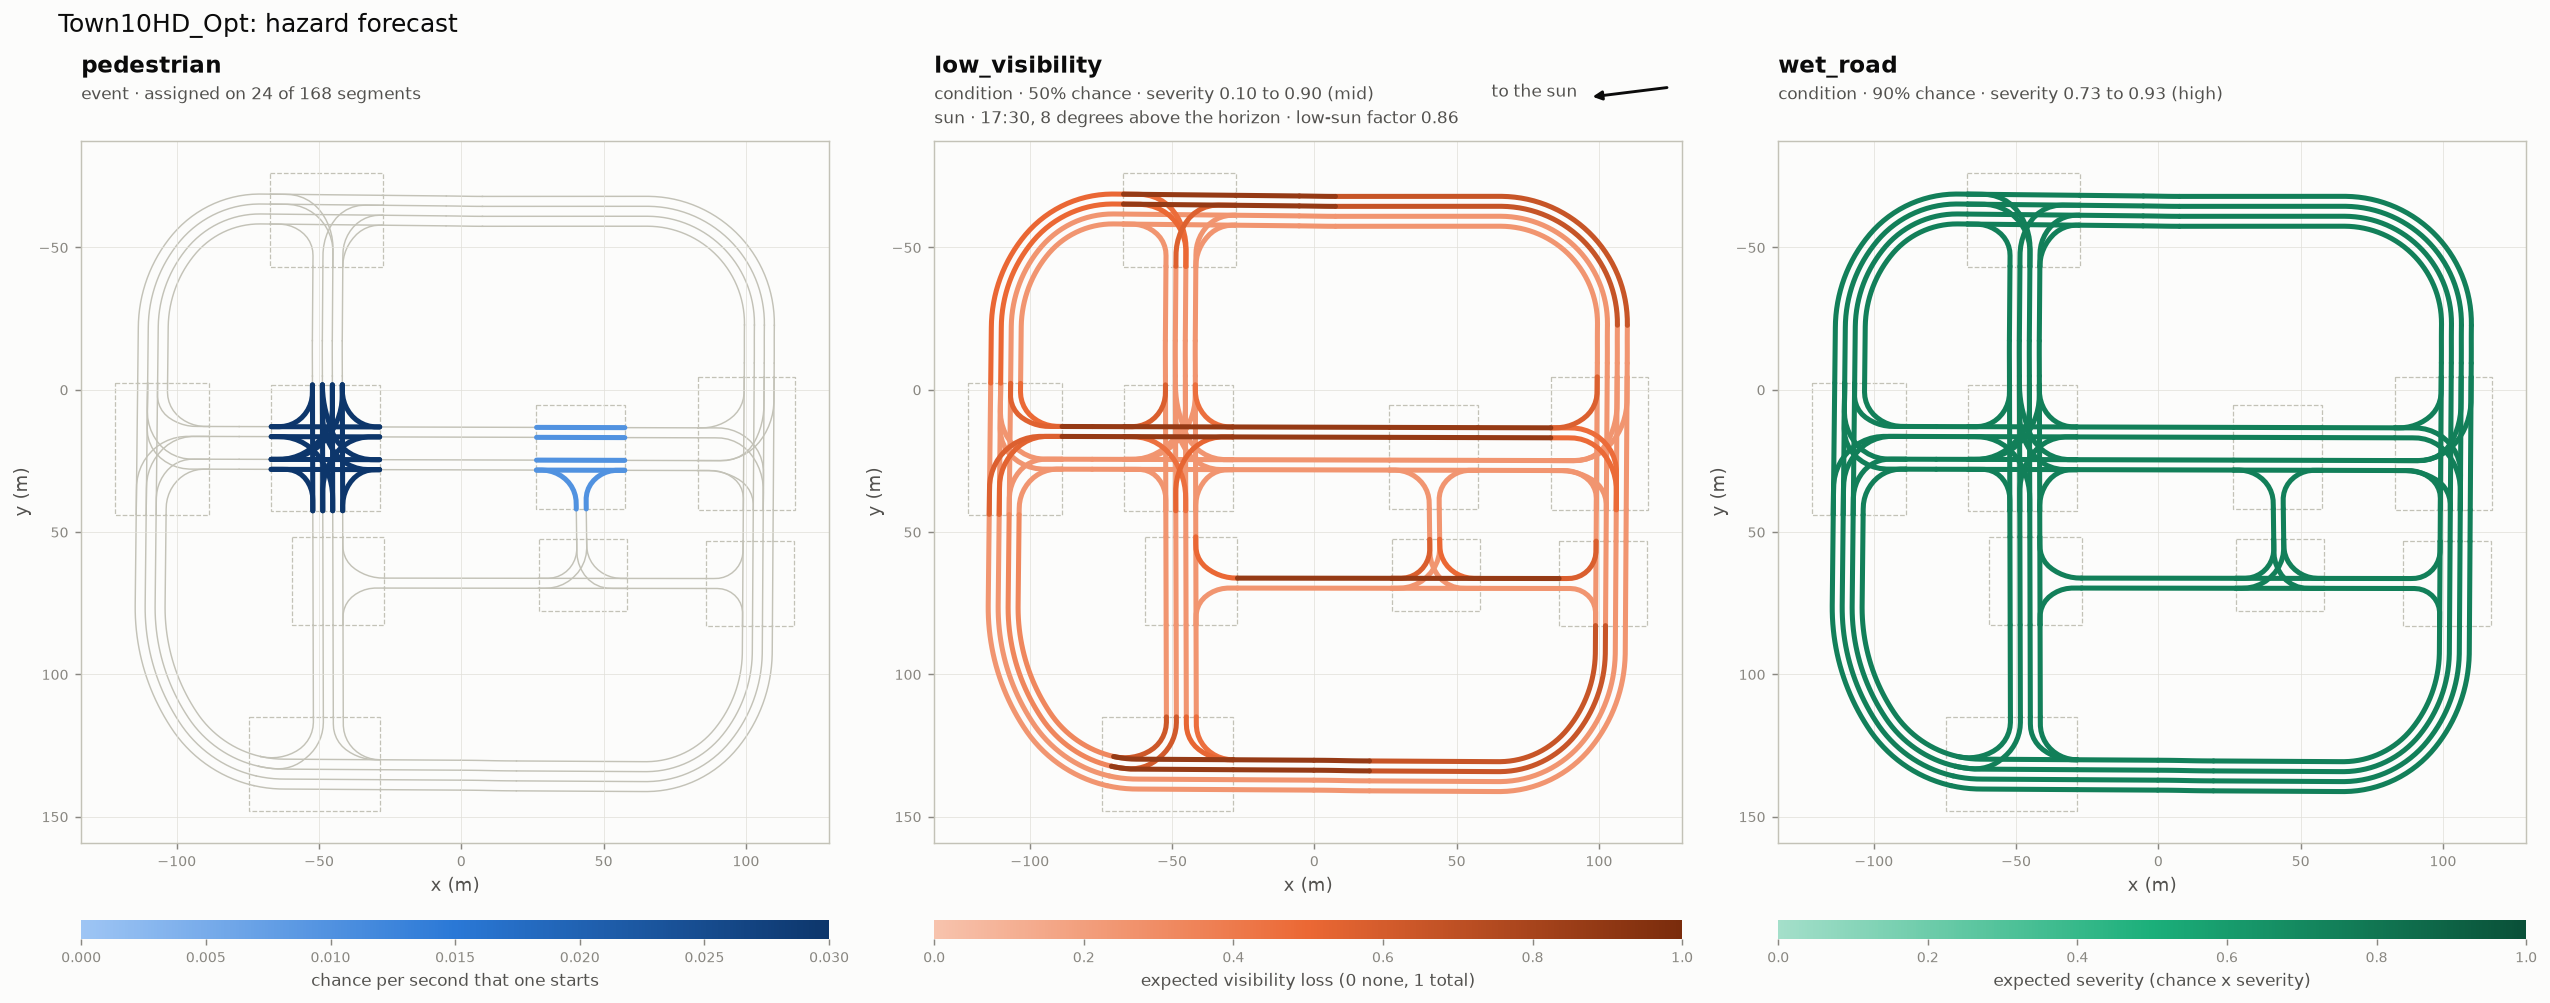

In [2]:
hazards = WorldHazardLibrary()
wrg = WorldRoadGraph.from_template("town10")

for lane in wrg.segments_in_junction(189):
    lane.assign_hazard_probability([(hazards.pedestrian, 0.03)])
for lane in wrg.segments_in_junction(841):
    lane.assign_hazard_probability([(hazards.pedestrian, 0.01)])
wrg.set_condition(hazards.wet_road, probability=0.9, severity="high", variability=0.1)
wrg.set_condition(hazards.low_visibility, probability=0.5, severity="mid", variability=0.4)
wrg.set_time_of_day(17.5)

figure = Visualize.hazards(wrg, hazards)

## Point A and Point B

A point on the map is a segment and an offset along it in meters. The template lists the map's spawn points, which are valid places to start and end.

In [3]:
A = wrg.spawn_points[18]
B = wrg.spawn_points[127]

print(f"{len(wrg.spawn_points)} spawn points")
print("A:", A)
print("B:", B)

155 spawn points
A: SegmentPosition(segment_id='r8.s0.l1', offset_m=13.72958511479122)
B: SegmentPosition(segment_id='r0.s0.l1', offset_m=0.0)


## What the Planner Reads

The planner turns the forecast into one number per segment, the **hazard score**. It is a weighted sum of:

- each event's chance per second on the segment,
- the expected visibility loss on that lane (rain or fog, plus the low sun where the lane faces it),
- the expected severity of every other condition.

Every weight is 1 unless the configuration says otherwise.

In [4]:
scores = Planner.hazard_scores(wrg)

for sid, note in (("r20.s0.l-1", "eastbound, away from the sun"),
                  ("r20.s0.l4", "westbound, into the sun"),
                  ("r255.s0.l-1", "through junction 189, with pedestrians")):
    print(f"{sid:13} {scores[sid]:.2f}   {note}")
print(f"\nlowest {min(scores.values()):.2f}, highest {max(scores.values()):.2f}")

r20.s0.l-1    1.00   eastbound, away from the sun
r20.s0.l4     1.63   westbound, into the sun
r255.s0.l-1   1.03   through junction 189, with pedestrians

lowest 1.00, highest 1.66


Rain or fog and the wet road are the same everywhere, so every segment starts at 1.00. A pedestrian chance of 0.03 per second adds almost nothing on top of that.

## Three Drivers

- **naive** takes the quickest route at the speed limits.
- **cautious** keeps the naive route and caps its speed at 20 km/h.
- **risk-aware** minimizes time plus `risk_scale` times the predicted penalty, choosing both the route and each speed.

On a segment, the penalty rate is its hazard score times (0.25 + (speed / 30 km/h)²). The 0.25 is hazard that accrues per second whatever the speed, so driving very slowly still costs something.

In [5]:
def summarize(route):
    speeds = [step.target_speed_kmh for step in route.steps]
    junctions = sorted({wrg.get_segment(sid).junction_id for sid in route.segment_ids} - {None})
    print(f"{route.mode:11} risk scale {route.risk_scale:<4g} {route.estimated_time_s:5.1f} s  {route.distance_m:4.0f} m  "
          f"penalty {route.predicted_penalty:5.1f}  speeds {min(speeds):g} to {max(speeds):g} km/h  junctions {junctions}")

naive = Planner.route(A, B, wrg, mode="naive")
cautious = Planner.route(A, B, wrg, mode="cautious")
aware = Planner.route(A, B, wrg, risk_scale=2)

for route in (naive, cautious, aware):
    summarize(route)
print("\nrisk-aware takes the naive route:", aware.segment_ids == naive.segment_ids)

naive       risk scale 0     59.7 s   498 m  penalty  83.5  speeds 30 to 30 km/h  junctions [23, 189, 468, 719]
cautious    risk scale 0     89.6 s   498 m  penalty  69.5  speeds 20 to 20 km/h  junctions [23, 189, 468, 719]
risk-aware  risk scale 2     71.4 s   498 m  penalty  75.6  speeds 22 to 26 km/h  junctions [23, 189, 468, 719]

risk-aware takes the naive route: True


With default weights the risk-aware driver slows down but does not change its route. The uniform conditions raise the cost of every segment equally, and the pedestrian chance is too small next to them to make junction 189 worth avoiding.

A weight sets how much one hazard counts. Weighting the pedestrian event at 20 puts its 0.03 per second on the same scale as the conditions.

In [6]:
config = PlannerConfig(weights={"pedestrian": 20.0})

naive = Planner.route(A, B, wrg, mode="naive", config=config)
cautious = Planner.route(A, B, wrg, mode="cautious", config=config)
aware = Planner.route(A, B, wrg, risk_scale=2, config=config)

for route in (naive, cautious, aware):
    summarize(route)

naive       risk scale 0     59.7 s   498 m  penalty  87.0  speeds 30 to 30 km/h  junctions [23, 189, 468, 719]
cautious    risk scale 0     89.6 s   498 m  penalty  72.5  speeds 20 to 20 km/h  junctions [23, 189, 468, 719]
risk-aware  risk scale 2     72.1 s   502 m  penalty  76.1  speeds 22 to 26 km/h  junctions [23, 468, 719]


`Visualize.routes` draws one map per route, shaded by target speed, with A and B marked. Segments where an event is forecast carry a wide pale band. The chart at the bottom shows each route's target speed along its distance.

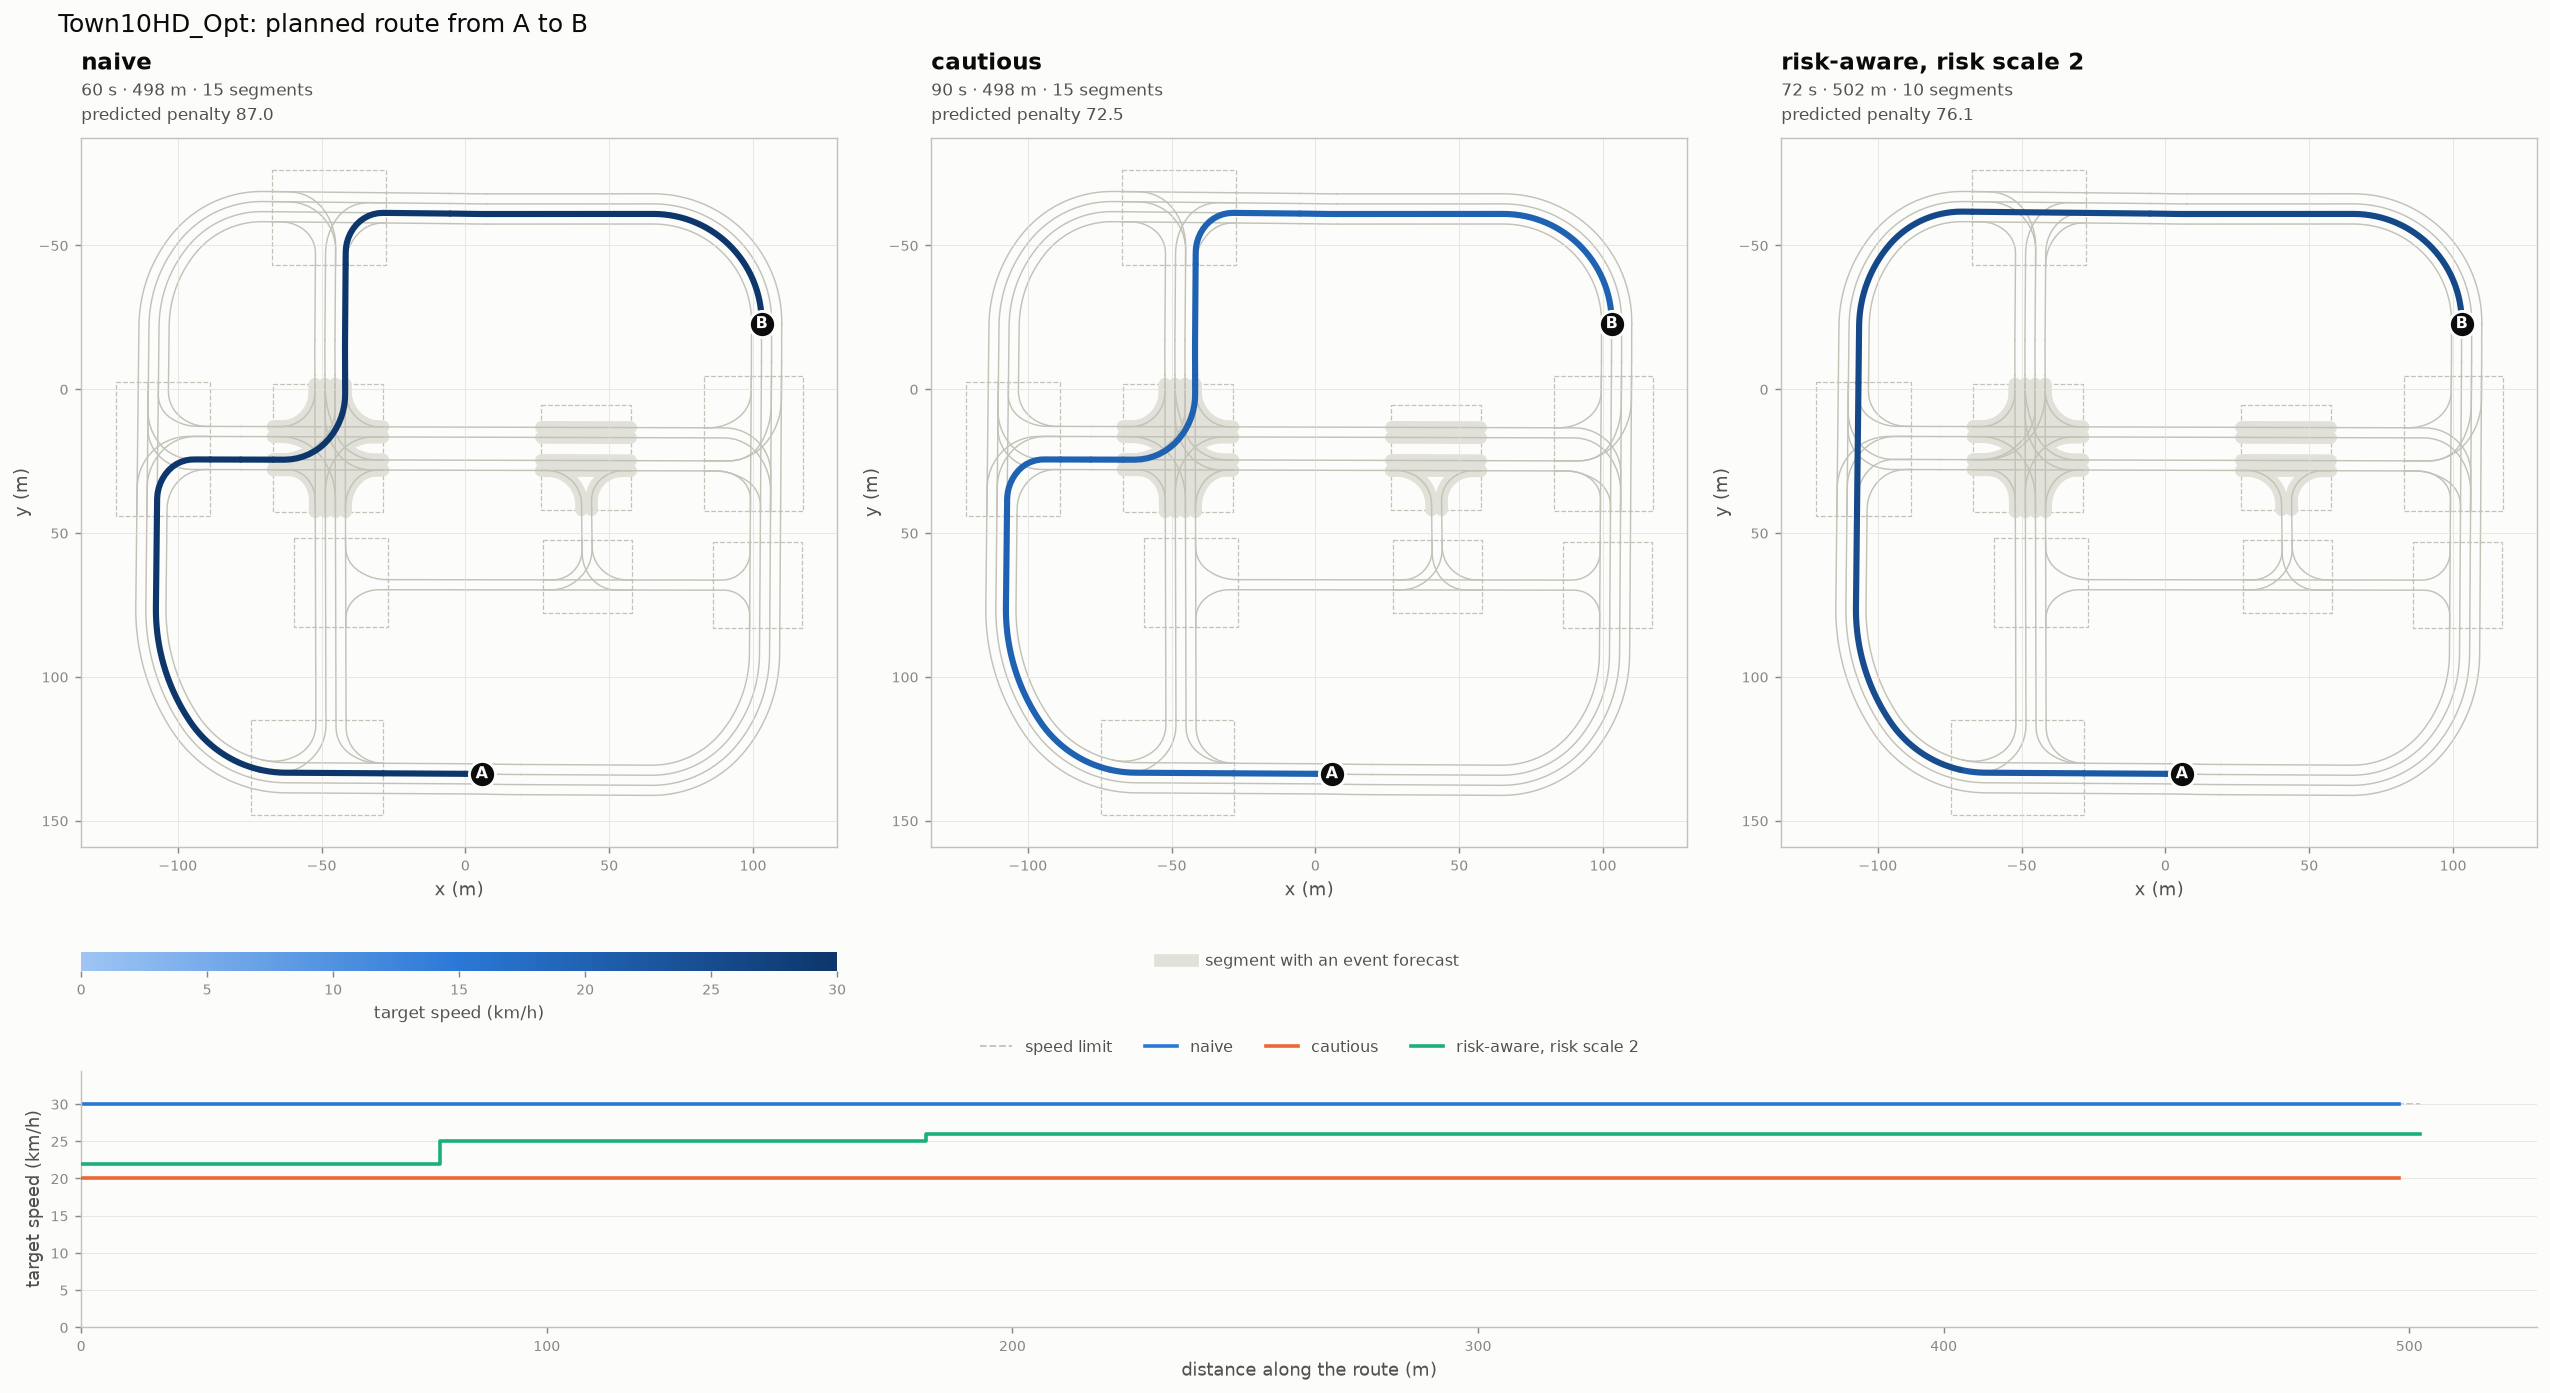

In [7]:
figure = Visualize.routes(wrg, [naive, cautious, aware])
figure.savefig(OUTPUT / "town10-routes.png", bbox_inches="tight")

The risk-aware route goes around junction 189. It is slowest on its first stretch, which heads west into the low sun.

## The Route Itself

A route is an ordered list of steps. Each step names a segment of the road graph by the same ID, the stretch of it to drive, and the target speed.

In [8]:
print(f"{'segment':13} {'from':>6} {'to':>6} {'km/h':>5} {'time s':>7} {'score':>6} {'penalty':>8}")
for step in aware.steps:
    print(f"{step.segment_id:13} {step.start_offset_m:6.1f} {step.end_offset_m:6.1f} {step.target_speed_kmh:5g} "
          f"{step.estimated_time_s:7.2f} {step.hazard_score:6.2f} {step.predicted_penalty:8.2f}")

first = wrg.get_segment(aware.steps[0].segment_id)
print(f"\nthe first step is on {first.id}: {first.length_m:.1f} m long, limit {first.speed_limit_kmh:g} km/h")

segment         from     to  km/h  time s  score  penalty
r8.s0.l1        13.7   19.5    22    0.95   1.63     1.22
r4.s0.l-1        0.0   28.4    22    4.64   1.63     5.97
r515.s0.l-1      0.0   42.8    22    7.00   1.63     8.97
r5.s0.l-1        0.0  104.4    25   15.03   1.09    15.41
r736.s0.l-1      0.0   46.2    26    6.39   1.00     6.40
r6.s0.l-1        0.0   82.7    26   11.45   1.00    11.46
r89.s0.l-1       0.0   39.3    26    5.44   1.00     5.45
r7.s0.l-1        0.0   22.5    26    3.11   1.00     3.11
r17.s0.l1        0.0   12.7    26    1.77   1.00     1.77
r10.s0.l1        0.0  117.6    26   16.29   1.00    16.30

the first step is on r8.s0.l1: 19.5 m long, limit 30 km/h


## Sweep the Risk Scale

A risk scale of 0 is the naive plan. Raising it trades time for a lower predicted penalty.

In [9]:
print(f"{'risk scale':>10} {'time s':>7} {'penalty':>8} {'distance m':>11} {'slowest km/h':>13}  through junction 189")
for risk_scale in (0, 0.5, 1, 2, 5, 10):
    route = Planner.route(A, B, wrg, risk_scale=risk_scale, config=config)
    through = any(wrg.get_segment(sid).junction_id == 189 for sid in route.segment_ids)
    print(f"{risk_scale:>10g} {route.estimated_time_s:7.1f} {route.predicted_penalty:8.1f} {route.distance_m:11.0f} "
          f"{min(step.target_speed_kmh for step in route.steps):13g}  {'yes' if through else 'no'}")

risk scale  time s  penalty  distance m  slowest km/h  through junction 189
         0    59.7     87.0         498            30  yes
       0.5    60.3     83.9         502            30  no
         1    60.9     83.2         502            28  no
         2    72.1     76.1         502            22  no
         5    92.0     69.6         502            18  no
        10   101.4     68.1         502            17  no


## Save and Load

A route records the map and the forecast it was planned from, so it can be checked against a world before it is driven.

In [10]:
path = OUTPUT / "town10-route-risk-aware.json.gz"
aware.save(path)

loaded = PlannerComputedWaypoints.load(path)
print("route reloads unchanged:", loaded == aware)
print("planned on this map:    ", loaded.graph_id == wrg.graph_id)
print("planned on this forecast:", loaded.forecast_hash == wrg.forecast_hash())

route reloads unchanged: True
planned on this map:     True
planned on this forecast: True


## Where the Planning Model Had to Change

The search and the pricing come unchanged from the team's first planner, called the first pass below: the same graph of segment entry and exit nodes, the same speed grid, the same penalty formula, the same three modes. What changed is what the forecast means.

1. **Three per-segment probabilities became one hazard score.** The first pass read a 0 to 1 value for pedestrian, visibility and wet road on every segment. Now the forecast has three different things: a per-second event chance per segment, a world-wide condition severity, and a sun effect per lane. `Planner.hazard_scores` folds them into the one number the pricing needs.
2. **The scales no longer match.** A pedestrian chance is about 0.01 to 0.05 per second, while a condition's expected severity runs up to 1. At equal weights the conditions outweigh the events, as the first run above shows. The weights need to be chosen deliberately.
3. **Conditions are uniform, so they change speed and not route.** A wet road slows the whole trip, even where there is nothing to brake for. Adding conditions to the score may be the wrong form: a condition makes an event more costly, which suggests multiplying an event's cost instead.
4. **Visibility is now directional.** The low sun raises the score only on lanes that face it, so the planner can slow down on those lanes or route around them. No such effect existed in the first pass.
5. **The planner uses expected values only.** It reads chance times severity for a condition and ignores how much the severity can vary.

Not yet brought over: following a route in CARLA, which belongs to the driver module.